Gabriel Lira Silva | RA: 177062

Yago Peixoto Koki  | RA: 164009

-----------Tarefas--------------

A, C, GIF --> Lira

B, D, E --> Yago



In [4]:
#Importando bibliotecas necessárias para o desenvolvimento
import math
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.gridspec as gridspec
from matplotlib.animation import FuncAnimation, PillowWriter # Biblioteca para gerar o GIF animado
from IPython.display import Image # Biblioteca para visualizar o GIF animado

#Definindo estilo para todos os gráficos
plt.style.use("seaborn-v0_8-whitegrid")

#Mensagem de confirmação
print("Ambiente preparado com sucesso!")

Ambiente preparado com sucesso!


 Numero original  Casas  Numero truncado  Erro absoluto   (trunc)  Erro relativo   (trunc)  Erro percentual (trunc)  Numero arredondado  Erro absoluto   (round)  Erro relativo   (round)  Erro percentual (round)
        3.141593      0           3.0000                 0.141593             4.507034e-02                 4.507034              3.0000                 0.141593             4.507034e-02                 4.507034
        3.141593      1           3.1000                 0.041593             1.323935e-02                 1.323935              3.1000                 0.041593             1.323935e-02                 1.323935
        3.141593      2           3.1400                 0.001593             5.069562e-04                 0.050696              3.1400                 0.001593             5.069562e-04                 0.050696
        3.141593      3           3.1410                 0.000593             1.886464e-04                 0.018865              3.1420                 0.00

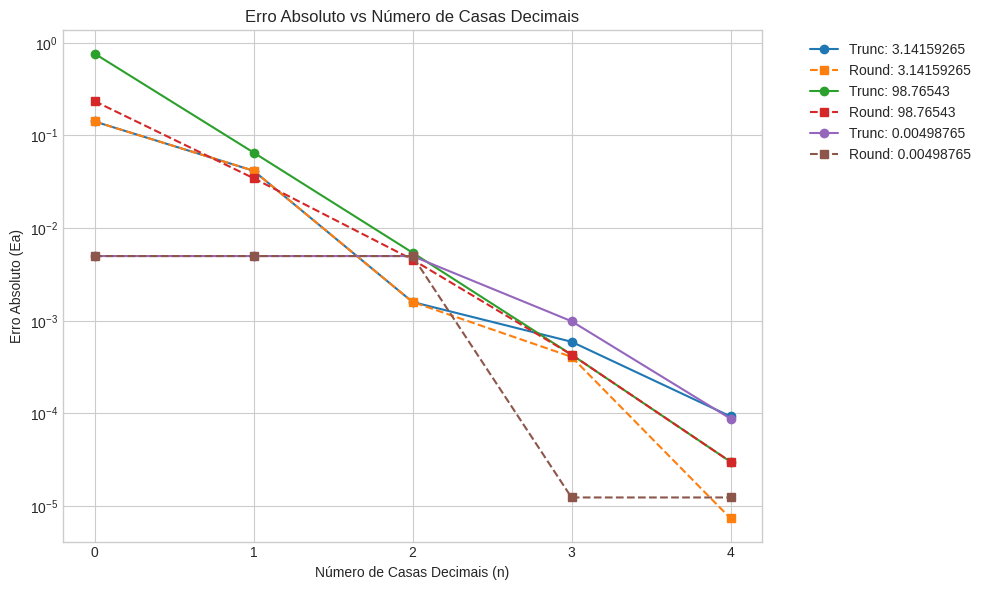

In [ ]:
#Tarefa A

# Definindo os valores dados pelo exercício
numeros = [3.14159265, 98.76543, 0.00498765]
casas = [0, 1, 2, 3, 4]


#1- Arredondamento e truncamento

# Função para truncar um número em uma determinada qtd. de casas
def truncar(numero, casas):
  # Calcula o fator que desloca a vírgula decimal
  fator = 10 ** casas

  valor_truncado = math.trunc(numero * fator) / fator

  # Retorna o número truncado
  return valor_truncado

# Função para arredondar um número em uma determinada qtd. de casas
def arredondar(numero, casas):

  # Calcula o valor arrendonado a partir da função "round"
  valor_arredondado = round(numero,casas)

  # Retorna o valor arredondado
  return valor_arredondado

# 2- Erros absoluto, relativo e percentual

# Função para calcular os erros absoluto, relativo e percentual
def calcula_erros(valor_referencia, valor_aproximado):

  # Calcula os erros
  erro_absoluto = abs(valor_referencia - valor_aproximado)
  erro_relativo = erro_absoluto / abs(valor_referencia)
  erro_percentual = erro_relativo * 100

  # Retorna os erros
  return erro_absoluto, erro_relativo, erro_percentual

# 3- Cálculo e montagem da tabela

linhas = []
for x in numeros:
  for n in casas:
    # Efetuando o truncamento
    numero_truncado = truncar(x, n)
    # Efetuando o cálculo dos erros
    erro_absoluto_truncado, erro_relativo_truncado, erro_percentual_truncado = calcula_erros(x, numero_truncado)

    # Efetuando o arredondamento
    numero_arredondado = arredondar(x, n)
    # Efetuando o cálculo dos erros
    erro_absoluto_arredondado, erro_relativo_arredondado, erro_percentual_arredondado = calcula_erros(x, numero_arredondado)

    linhas.append({
        'Numero original': x,
        'Casas': n,
        'Numero truncado': numero_truncado,
        'Erro absoluto   (trunc)': erro_absoluto_truncado,
        'Erro relativo   (trunc)': erro_relativo_truncado,
        'Erro percentual (trunc)': erro_percentual_truncado,
        'Numero arredondado': numero_arredondado,
        'Erro absoluto   (round)': erro_absoluto_arredondado,
        'Erro relativo   (round)': erro_relativo_arredondado,
        'Erro percentual (round)': erro_percentual_arredondado
    })

df = pd.DataFrame(linhas)
print(df.to_string(index=False))

# 4- Gráfico em escala logarítmica de Ea em função de n

# Define o tamanho da figura
plt.figure(figsize=(10, 6))

# Percorre cada número original para criar linhas independentes no gráfico
for x in numeros:
    # Filtra o DataFrame apenas para o número atual
    df_filtrado = df[df['Numero original'] == x]

    # Eixo X: número de casas
    eixo_x = df_filtrado['Casas']

    # Plota o Erro Absoluto de Truncamento (linha contínua com marcadores de círculo)
    plt.plot(eixo_x, df_filtrado['Erro absoluto   (trunc)'],
             marker='o', linestyle='-', label=f'Trunc: {x}')

    # Plota o Erro Absoluto de Arredondamento (linha tracejada com marcadores de quadrado)
    plt.plot(eixo_x, df_filtrado['Erro absoluto   (round)'],
             marker='s', linestyle='--', label=f'Round: {x}')

# Aplica a escala logarítmica no eixo Y
plt.yscale('log')

# Configurações de rótulos e título
plt.xlabel('Número de Casas Decimais (n)')
plt.ylabel('Erro Absoluto (Ea)')
plt.title('Erro Absoluto vs Número de Casas Decimais')

# Garante que o eixo X mostre apenas os números inteiros correspondentes às casas
plt.xticks(casas)

# Adiciona a legenda fora da área do gráfico para não sobrepor as linhas
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# Ajusta o layout para evitar cortes na imagem
plt.tight_layout()

# Exibe o gráfico
plt.show()

## Responda: arredondar sempre gera erro menor ou igual ao truncamento? Justifique com os resultados.

**Resposta:** Sim! A partir dos resultados obtidos podemos concluir que arredondar sempre gera um erro menor ou igual ao truncamento.

Ao observarmos o gráfico, notamos que as linhas tracejadas (que representam o erro de arredondamento) estão sempre abaixo ou exatamente sobrepostas às linhas contínuas correspondentes (que representam o erro de truncamento). Em nenhum momento uma linha tracejada fica acima da sua respectiva linha contínua.

B.1:


In [ ]:
# Guardando valores em um vetor
PA = [121.7, 120.4, 122.1, 119.8, 121.2, 120.9, 122.4, 121.0, 120.2, 121.5]

# Função do numpy para cálculo da média
media = np.mean(PA)
# print(media)

PAround = []
PAtrunc = []

for pressao in PA:

    PAround.append(round(pressao))
    PAtrunc.append(math.trunc(pressao))
# Dados

print(f"dados originais: {PA}, média: {np.mean(PA)}, mínimo: {np.min(PA)}, máximo: {np.max(PA)}, amplitude: {np.ptp(PA)}, desvio padrão amostral: {np.std(PA, ddof=1)} ")


print(f"dados arredondados: {PAround}, média: {np.mean(PAround)}, mínimo: {np.min(PAround)}, máximo: {np.max(PAround)}, amplitude: {np.ptp(PAround)}, desvio padrão amostral: {np.std(PAround, ddof=1)} ")
print(f"dados truncados: {PAtrunc}, média: {np.mean(PAtrunc)}, mínimo: {np.min(PAtrunc)}, máximo: {np.max(PAtrunc)}, amplitude: {np.ptp(PAtrunc)}, desvio padrão amostral: {np.std(PAtrunc, ddof=1)}  ")


# Cálculo dos erros arredondados:
EAA =  np.abs(np.mean(PA) - np.mean(PAround))
ERA = EAA/np.abs(np.mean(PA))
EPA =  100 * ERA

# Cálculo dos erros truncados:
EAT =  np.mean(PA) - np.mean(PAtrunc)
ERT = EAT/np.mean(PA)
EPT = 100 * ERT

print(f"ARREDONDADO: Erro absoluto: {EAA}. Erro relativo: {ERA}. Erro percentual: {EPA}%")
print(f"TRUNCADO: Erro absoluto: {EAT}. Erro relativo: {ERT}. Erro percentual: {EPT}%")



B.2:


In [ ]:
# Gráfico de Medições de Pressão arterial
medidas = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

x = np.arange(len(medidas))
largura = 0.2




plt.bar(x - largura, PA, largura, label='Dados Originais', color='b')
plt.bar(x, PAround, largura, label='Arredondados', color='g')
plt.bar(x + largura, PAtrunc, largura, label='Truncados', color='r')

plt.xlabel('Medidas')
plt.ylabel('Valores (mmHg)')
plt.title('Medições de Pressão arterial')
plt.xticks(x, medidas)
plt.legend()

plt.ylim(110, 125)

plt.tight_layout()
plt.show()

In [ ]:
# Gráfico de erros percentuais

medidas = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

x = np.arange(len(medidas))
largura = 0.2




plt.bar(x - largura, EPA, largura, label='Arredondados', color='b')
plt.bar(x, EPT, largura, label='Truncados', color='g')


plt.xlabel('Erros')
plt.ylabel('Valores')
plt.title('Erros Percentuais')
plt.xticks(x, medidas)
plt.legend()



plt.tight_layout()
plt.show()

In [ ]:
# Histograma dos dados originais em um intervalo de 0.5

plt.hist(PA, bins=[119.5, 120, 120.5, 121, 121.5, 122, 122.5], edgecolor='black')
plt.xlabel('Valores de PA')
plt.ylabel('Frequência')
plt.title('Histograma de PA')

plt.grid(axis='y', linestyle='-.', alpha=0.7)

print("Histograma dos dados originais em um intervalo de 0.5")
print("\n")
plt.show()


In [ ]:
# Histograma dos dados inteiros arredondados

plt.hist(PAround, bins=[119.5, 120.5, 121.5, 122.5], edgecolor='black')

plt.xlabel('Valores Inteiros de Pressão arterial arredondado')
plt.ylabel('Frequência')
plt.title('Histograma de PA')
plt.xticks([120, 121, 122])
plt.grid(axis='y', linestyle='-.', alpha=0.7)

print("Histograma dos dados inteiros arredondados")
print("\n")

plt.show()

In [ ]:
# Gráfico de erros absolutos

medidas = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

x = np.arange(len(medidas))
largura = 0.2




plt.bar(x - largura, EAA, largura, label='Arredondados', color='b')
plt.bar(x, EAT, largura, label='Truncados', color='g')


plt.xlabel('Erros')
plt.ylabel('Valores')
plt.title('Erros Absolutos')
plt.xticks(x, medidas)
plt.legend()



plt.tight_layout()
plt.show()

================ RESULTADOS C.1 ================
                 Cenário   Q_truncado  Q_arredondado    Ea(trunc)    Ea(round)
1. Referência (Sem erro) 2.757421e-07   2.757421e-07 0.000000e+00 0.000000e+00
  2. Apenas r aproximado 2.757421e-07   2.757421e-07 0.000000e+00 0.000000e+00
 3. Apenas mu aproximado 3.216991e-07   2.412743e-07 4.595701e-08 3.446776e-08
 4. Apenas dp aproximado 2.757421e-07   2.757421e-07 0.000000e+00 0.000000e+00
    5. Todas simultâneas 3.216991e-07   2.412743e-07 4.595701e-08 3.446776e-08




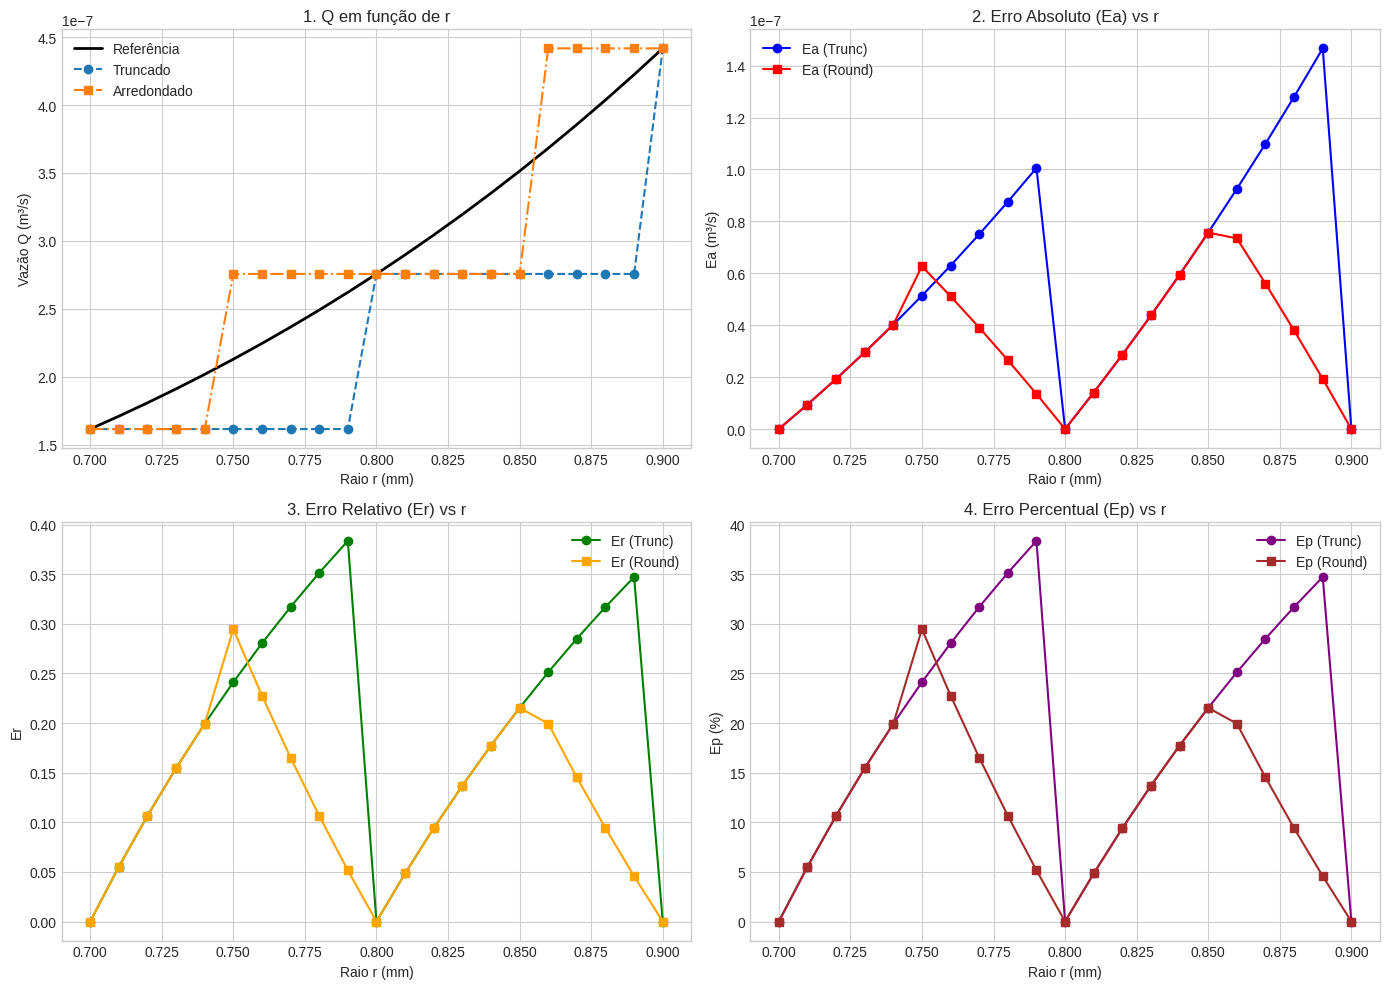

In [ ]:
# Funções Auxiliares
def truncar(numero, casas):
    fator = 10 ** casas
    return math.trunc(numero * fator) / fator

def arredondar(numero, casas):
    return round(numero, casas)

def calcula_erros(valor_referencia, valor_aproximado):
    erro_absoluto = abs(valor_referencia - valor_aproximado)
    if valor_referencia != 0:
        erro_relativo = erro_absoluto / abs(valor_referencia)
    else:
        erro_relativo = 0
    erro_percentual = erro_relativo * 100
    return erro_absoluto, erro_relativo, erro_percentual

# Função para calcular Q (Hagen-Poiseuille)
def calcular_Q(r_mm, L_m, mu_Pas, dp_Pa):
    # Converte o raio de mm para metros para o cálculo
    r_m = r_mm * 1e-3
    Q = (math.pi * (r_m ** 4) * dp_Pa) / (8 * mu_Pas * L_m)
    return Q

# C.1 - Precisão das Variáveis
print("================ RESULTADOS C.1 ================")
# Valores de referência adotados
r_ref = 0.80       # mm
L_ref = 0.20       # m
mu_ref = 3.5e-3    # Pa.s (0.0035)
dp_ref = 1200.0    # Pa

Q_ref = calcular_Q(r_ref, L_ref, mu_ref, dp_ref)
cenarios = []

# 1- Todos os valores fornecidos
cenarios.append({'Cenário': '1. Referência (Sem erro)', 'Q_truncado': Q_ref, 'Q_arredondado': Q_ref, 'Ea(trunc)': 0.0, 'Ea(round)': 0.0})

# 2- r arredondado e truncado para 1 casa decimal
r_t = truncar(r_ref, 1)
r_r = arredondar(r_ref, 1)
Q_t2 = calcular_Q(r_t, L_ref, mu_ref, dp_ref)
Q_r2 = calcular_Q(r_r, L_ref, mu_ref, dp_ref)
ea_t2, _, _ = calcula_erros(Q_ref, Q_t2)
ea_r2, _, _ = calcula_erros(Q_ref, Q_r2)
cenarios.append({'Cenário': '2. Apenas r aproximado', 'Q_truncado': Q_t2, 'Q_arredondado': Q_r2, 'Ea(trunc)': ea_t2, 'Ea(round)': ea_r2})

# 3- mu arredondado e truncado para 3 casas decimais
mu_t = truncar(mu_ref, 3) # 0.0035 vira 0.003
mu_r = arredondar(mu_ref, 3) # 0.0035 vira 0.004
Q_t3 = calcular_Q(r_ref, L_ref, mu_t, dp_ref)
Q_r3 = calcular_Q(r_ref, L_ref, mu_r, dp_ref)
ea_t3, _, _ = calcula_erros(Q_ref, Q_t3)
ea_r3, _, _ = calcula_erros(Q_ref, Q_r3)
cenarios.append({'Cenário': '3. Apenas mu aproximado', 'Q_truncado': Q_t3, 'Q_arredondado': Q_r3, 'Ea(trunc)': ea_t3, 'Ea(round)': ea_r3})

# 4- dp arredondado e truncado para centenas (casas = -2)
dp_t = truncar(dp_ref, -2)
dp_r = arredondar(dp_ref, -2)
Q_t4 = calcular_Q(r_ref, L_ref, mu_ref, dp_t)
Q_r4 = calcular_Q(r_ref, L_ref, mu_ref, dp_r)
ea_t4, _, _ = calcula_erros(Q_ref, Q_t4)
ea_r4, _, _ = calcula_erros(Q_ref, Q_r4)
cenarios.append({'Cenário': '4. Apenas dp aproximado', 'Q_truncado': Q_t4, 'Q_arredondado': Q_r4, 'Ea(trunc)': ea_t4, 'Ea(round)': ea_r4})

# 5- Todas as aproximações simultaneamente
Q_t5 = calcular_Q(r_t, L_ref, mu_t, dp_t)
Q_r5 = calcular_Q(r_r, L_ref, mu_r, dp_r)
ea_t5, _, _ = calcula_erros(Q_ref, Q_t5)
ea_r5, _, _ = calcula_erros(Q_ref, Q_r5)
cenarios.append({'Cenário': '5. Todas simultâneas', 'Q_truncado': Q_t5, 'Q_arredondado': Q_r5, 'Ea(trunc)': ea_t5, 'Ea(round)': ea_r5})

# Exibir tabela C.1
df_c1 = pd.DataFrame(cenarios)
print(df_c1.to_string(index=False))
print("\n")

# C.1 - Sensibilidade

# Variação do raio de 0.70 a 0.90 mm (21 pontos para pegar de 0.01 em 0.01)
raios = np.linspace(0.70, 0.90, 21)
resultados_c2 = []

for r in raios:
    Q_ref_r = calcular_Q(r, L_ref, mu_ref, dp_ref)

    r_t = truncar(r, 1)
    r_r = arredondar(r, 1)

    Q_t = calcular_Q(r_t, L_ref, mu_ref, dp_ref)
    Q_r = calcular_Q(r_r, L_ref, mu_ref, dp_ref)

    ea_t, er_t, ep_t = calcula_erros(Q_ref_r, Q_t)
    ea_r, er_r, ep_r = calcula_erros(Q_ref_r, Q_r)

    resultados_c2.append({
        'r': r, 'Q_ref': Q_ref_r,
        'Q_trunc': Q_t, 'Q_round': Q_r,
        'Ea_trunc': ea_t, 'Ea_round': ea_r,
        'Er_trunc': er_t, 'Er_round': er_r,
        'Ep_trunc': ep_t, 'Ep_round': ep_r
    })

df_c2 = pd.DataFrame(resultados_c2)

# Criando figura com 4 subplots (2x2)
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# 1- Q em função de r
axs[0, 0].plot(df_c2['r'], df_c2['Q_ref'], label='Referência', color='black', linewidth=2)
axs[0, 0].plot(df_c2['r'], df_c2['Q_trunc'], label='Truncado', linestyle='--', marker='o')
axs[0, 0].plot(df_c2['r'], df_c2['Q_round'], label='Arredondado', linestyle='-.', marker='s')
axs[0, 0].set_title('1. Q em função de r')
axs[0, 0].set_xlabel('Raio r (mm)')
axs[0, 0].set_ylabel('Vazão Q (m³/s)')
axs[0, 0].legend()
axs[0, 0].grid(True)

# 2- Erro Absoluto de Q em função de r
axs[0, 1].plot(df_c2['r'], df_c2['Ea_trunc'], label='Ea (Trunc)', marker='o', color='blue')
axs[0, 1].plot(df_c2['r'], df_c2['Ea_round'], label='Ea (Round)', marker='s', color='red')
axs[0, 1].set_title('2. Erro Absoluto (Ea) vs r')
axs[0, 1].set_xlabel('Raio r (mm)')
axs[0, 1].set_ylabel('Ea (m³/s)')
axs[0, 1].legend()
axs[0, 1].grid(True)

# 3- Erro Relativo de Q em função de r
axs[1, 0].plot(df_c2['r'], df_c2['Er_trunc'], label='Er (Trunc)', marker='o', color='green')
axs[1, 0].plot(df_c2['r'], df_c2['Er_round'], label='Er (Round)', marker='s', color='orange')
axs[1, 0].set_title('3. Erro Relativo (Er) vs r')
axs[1, 0].set_xlabel('Raio r (mm)')
axs[1, 0].set_ylabel('Er')
axs[1, 0].legend()
axs[1, 0].grid(True)

# 4- Erro Percentual de Q em função de r
axs[1, 1].plot(df_c2['r'], df_c2['Ep_trunc'], label='Ep (Trunc)', marker='o', color='purple')
axs[1, 1].plot(df_c2['r'], df_c2['Ep_round'], label='Ep (Round)', marker='s', color='brown')
axs[1, 1].set_title('4. Erro Percentual (Ep) vs r')
axs[1, 1].set_xlabel('Raio r (mm)')
axs[1, 1].set_ylabel('Ep (%)')
axs[1, 1].legend()
axs[1, 1].grid(True)

plt.tight_layout()
plt.show()

##Explique por que o erro no raio é amplificado na vazão. Relacione sua resposta ao expoente quatro.

Resposta: de acordo com a equação de Hagen-Poiseuille, a vazão Q é diretamente proporcional ao raio, elevado à quarta potência:

$Q/r^4 = CTE$ ou $Q = r^4 . CTE$

Sabemos que a derivada de Q em relação a r nos dá o erro absoluto propagado:

$dQ = 4 \cdot CTE \cdot r^3 \cdot dr$

E, calculando o erro relativo na vazão ($dQ/Q$):

$\frac{dQ}{Q} = \frac{4 \cdot CTE \cdot r^3 \cdot dr}{CTE \cdot r^4} = 4 \cdot \frac{dr}{r}$

Concluímos que o erro relativo na vazão ($Q$) é, aproximadamente, 4 vezes maior que o erro relativo cometido ao medir o raio ($r$).

D.1:

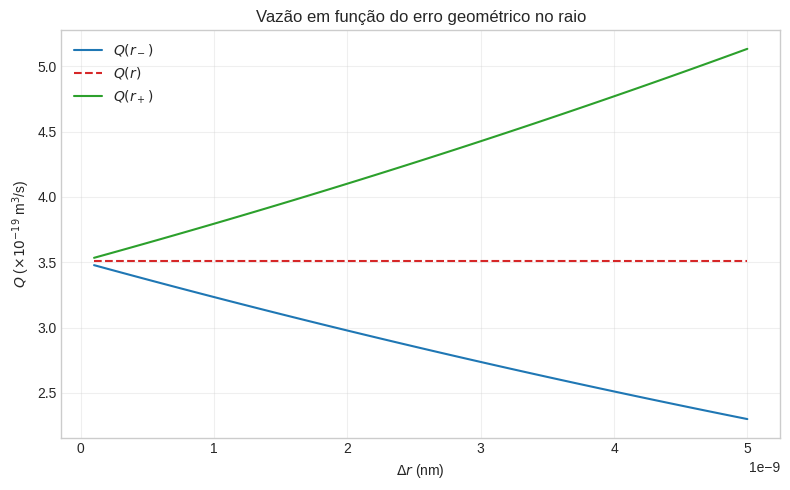

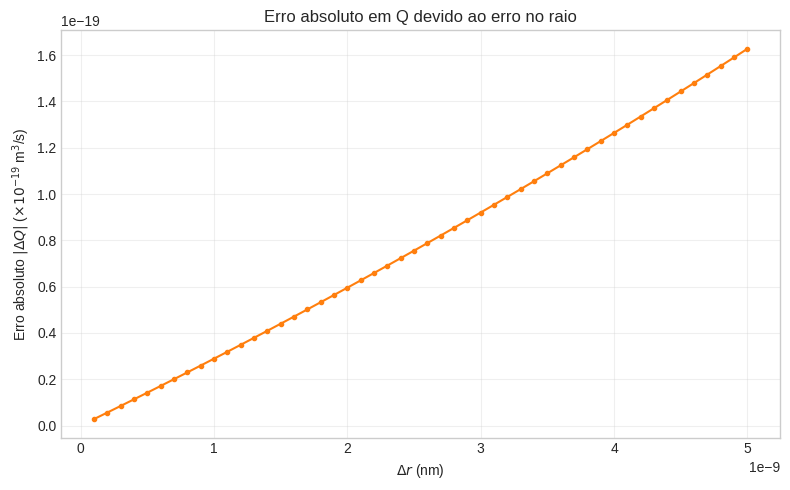

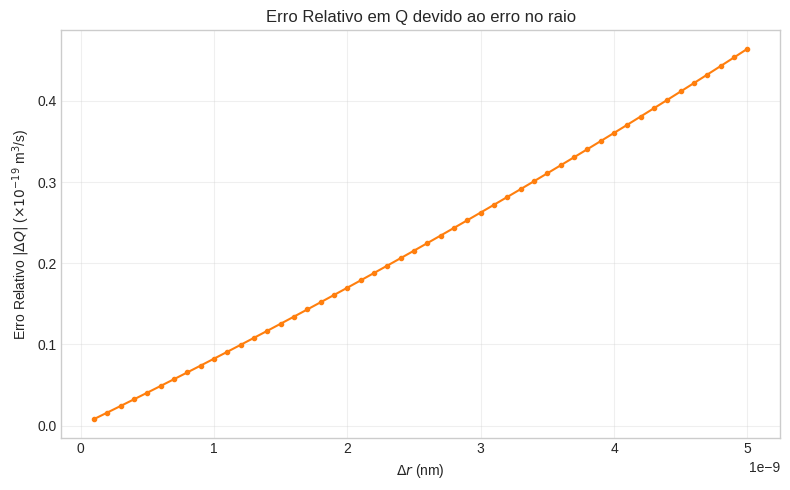

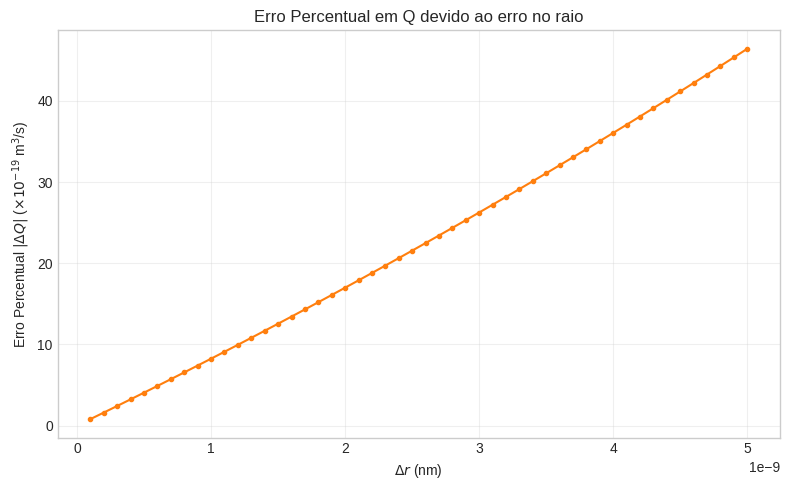

In [ ]:
r = 50e-9 #raio do duto [m]

L = 10e-6 #comprimento do duto [m]

mu = 3.5e-3 #viscosidade dinâmica do fluido

Dp = 5000 #Pa

def Q(r):
    return math.pi * r**4 *Dp / (8 * mu * L)

# 1

erros = np.arange(0.1, 5.1, 0.1)
erros_e9 = erros * 1e-9


rnegativo = []

rpositivo = []

for n in erros_e9:
  # Assuming 'n' represents a percentage error (e.g., 0.1 means 0.1%),
  # and rnegativo means calculating r with a negative error percentage.
  rnegativo.append(r - n)

  rpositivo.append(r + n)

# Convert lists to numpy arrays to enable element-wise operations with the Q function
rnegativo_np = np.array(rnegativo)
rpositivo_np = np.array(rpositivo)

Qnom = Q(r)
Qnegativo = Q(rnegativo_np)
Qpositivo = Q(rpositivo_np)


plt.figure(figsize=(8, 5))
plt.plot(erros_e9, Qnegativo * 1e19, label=r'$Q(r_-)$', color='tab:blue')
plt.plot(erros_e9, np.full_like(erros_e9, Qnom * 1e19), label=r'$Q(r)$',
         color='tab:red', linestyle='--')
plt.plot(erros_e9, Qpositivo * 1e19, label=r'$Q(r_+)$', color='tab:green')
plt.xlabel(r'$\Delta r$ (nm)')
plt.ylabel(r'$Q$ ($ \times 10^{-19}$ m$^3$/s)')
plt.title('Vazão em função do erro geométrico no raio')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



# 2

erro_abs = np.maximum(np.abs(Qnegativo - Qnom), np.abs(Qpositivo - Qnom))


plt.figure(figsize=(8, 5))
plt.plot(erros_e9, erro_abs, color='tab:orange', marker='o', markersize=3)

plt.xlabel(r'$\Delta r$ (nm)')
plt.ylabel(r'Erro absoluto $|\Delta Q|$ ($\times 10^{-19}$ m$^3$/s)')
plt.title('Erro absoluto em Q devido ao erro no raio')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3

erro_rel = erro_abs / Qnom

plt.figure(figsize=(8, 5))
plt.plot(erros_e9, erro_rel, color='tab:orange', marker='o', markersize=3)

plt.xlabel(r'$\Delta r$ (nm)')
plt.ylabel(r'Erro Relativo $|\Delta Q|$ ($\times 10^{-19}$ m$^3$/s)')
plt.title('Erro Relativo em Q devido ao erro no raio')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 4

erro_pct = erro_rel * 100

plt.figure(figsize=(8, 5))
plt.plot(erros_e9, erro_pct, color='tab:orange', marker='o', markersize=3)

plt.xlabel(r'$\Delta r$ (nm)')
plt.ylabel(r'Erro Percentual $|\Delta Q|$ ($\times 10^{-19}$ m$^3$/s)')
plt.title('Erro Percentual em Q devido ao erro no raio')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

D.2:


In [ ]:


# ---------- parâmetros (SI) ----------
r_val  = 50e-9      # raio nominal [m]
L_val  = 10e-6      # comprimento [m]
mu_val = 3.5e-3     # viscosidade [Pa.s]
dp_val = 5000       # diferença de pressão [Pa]

def Q(rr, L, mu, dp):
    """Vazão pela lei de Hagen-Poiseuille."""
    return np.pi * rr**4 * dp / (8 * mu * L)


# =====================================================================
# PARTE 1 — comparação float32 vs float64
# =====================================================================
print("=" * 70)
print("PARTE 1: r^4 e Q em float32 vs float64")
print("=" * 70)

for dtype, nome in [(np.float32, "float32"), (np.float64, "float64")]:
    r  = dtype(r_val)
    L  = dtype(L_val)
    mu = dtype(mu_val)
    dp = dtype(dp_val)

    r4 = r**4
    Qv = Q(r, L, mu, dp)
    eps = np.finfo(dtype).eps

    print(f"\n--- {nome} ---")
    print(f"r^4        = {r4!r}")
    print(f"Q          = {Qv!r}")
    print(f"eps ({nome}) = {eps!r}")

# valores para comparação (calculados separadamente em cada precisão)
r32, L32, mu32, dp32 = np.float32(r_val), np.float32(L_val), np.float32(mu_val), np.float32(dp_val)
r64, L64, mu64, dp64 = np.float64(r_val), np.float64(L_val), np.float64(mu_val), np.float64(dp_val)

r4_32 = r32**4
r4_64 = r64**4
Q32 = Q(r32, L32, mu32, dp32)
Q64 = Q(r64, L64, mu64, dp64)

diff_abs_r4 = abs(float(r4_64) - float(r4_32))
diff_rel_r4 = diff_abs_r4 / float(r4_64)

diff_abs_Q = abs(float(Q64) - float(Q32))
diff_rel_Q = diff_abs_Q / float(Q64)

print("\n" + "=" * 70)
print("Diferenças float64 vs float32")
print("=" * 70)
print(f"r^4:  diferença absoluta = {diff_abs_r4:.6e}   diferença relativa = {diff_rel_r4:.6e}")
print(f"Q:    diferença absoluta = {diff_abs_Q:.6e}   diferença relativa = {diff_rel_Q:.6e}")
print(f"\neps(float32) = {np.finfo(np.float32).eps:.6e}")
print(f"eps(float64) = {np.finfo(np.float64).eps:.6e}")


# =====================================================================
# PARTE 2 — δ1 vs δ2 e cancelamento para Δr/r pequenos
# =====================================================================
print("\n" + "=" * 70)
print("PARTE 2: δ1 vs δ2 para Δr/r decrescente (cancelamento)")
print("=" * 70)

def delta1(r, dr, L, mu, dp, dtype):
    r = dtype(r); dr = dtype(dr); L = dtype(L); mu = dtype(mu); dp = dtype(dp)
    Qr  = Q(r, L, mu, dp)
    Qdr = Q(r + dr, L, mu, dp)
    return (Qdr - Qr) / Qr

def delta2(r, dr, dtype):
    r = dtype(r); dr = dtype(dr)
    return (1 + dr / r) ** 4 - 1

# Δr/r decrescendo: 1e-2, 1e-3, ..., 1e-10
razoes = [10.0**(-k) for k in range(2, 11)]

for dtype, nome in [(np.float64, "float64"), (np.float32, "float32")]:
    print(f"\n--- precisão: {nome} ---")
    print(f"{'Δr/r':>12} {'δ1':>22} {'δ2':>22} {'|δ1-δ2|':>14}")
    for razao in razoes:
        dr = r_val * razao
        d1 = delta1(r_val, dr, L_val, mu_val, dp_val, dtype)
        d2 = delta2(r_val, dr, dtype)
        diff = abs(float(d1) - float(d2))
        print(f"{razao:12.1e} {float(d1):22.10e} {float(d2):22.10e} {diff:14.3e}")



PARTE 1: r^4 e Q em float32 vs float64

--- float32 ---
r^4        = np.float32(6.2500004e-30)
Q          = np.float32(3.5062423e-19)
eps (float32) = np.float32(1.1920929e-07)

--- float64 ---
r^4        = np.float64(6.249999999999999e-30)
Q          = np.float64(3.506241800881465e-19)
eps (float64) = np.float64(2.220446049250313e-16)

Diferenças float64 vs float32
r^4:  diferença absoluta = 3.959774e-37   diferença relativa = 6.335639e-08
Q:    diferença absoluta = 5.228628e-26   diferença relativa = 1.491234e-07

eps(float32) = 1.192093e-07
eps(float64) = 2.220446e-16

PARTE 2: δ1 vs δ2 para Δr/r decrescente (cancelamento)

--- precisão: float64 ---
        Δr/r                     δ1                     δ2        |δ1-δ2|
     1.0e-02       4.0604010000e-02       4.0604010000e-02      3.608e-16
     1.0e-03       4.0060040010e-03       4.0060040010e-03      2.238e-16
     1.0e-04       4.0006000400e-04       4.0006000400e-04      1.296e-17
     1.0e-05       4.0000600004e-05       4.

D.3:

Quando a escala geométrica diminui, a razão superfície/volume não permanece constante: como a área de superfície escala com o quadrado do comprimento característico (∝ r²) e o volume escala com o cubo (∝ r³), essa razão cresce como 1/r — ou seja, dobra se o raio for reduzido à metade, e cresce sem limite conforme r → 0. Em um nanocateter, isso significa que uma fração muito maior das moléculas do fluido está fisicamente próxima à parede do canal, de modo que efeitos de superfície (atrito viscoso na parede, camadas de deslizamento, forças de van der Waals, interações eletrostáticas) passam a competir em pé de igualdade com — ou até dominar sobre — os efeitos de volume (inércia, gradiente de pressão "livre"). Do ponto de vista fluidodinâmico, isso se reflete em um número de Reynolds muito baixo (regime fortemente viscoso, escoamento laminar dominado por atrito) e em um gradiente de velocidade extremamente acentuado próximo à parede, já que praticamente todo o perfil de velocidade está dentro da camada limite viscosa. É por isso que, em escalas nanométricas, hipóteses que funcionam bem macroscopicamente — como a própria lei de Hagen–Poiseuille assumindo escoamento contínuo e condição de não-deslizamento na parede — podem deixar de ser fisicamente válidas mesmo que o cálculo numérico continue sendo executado sem erro: a aritmética permanece correta, mas o modelo físico subjacente perde a validade.


E:

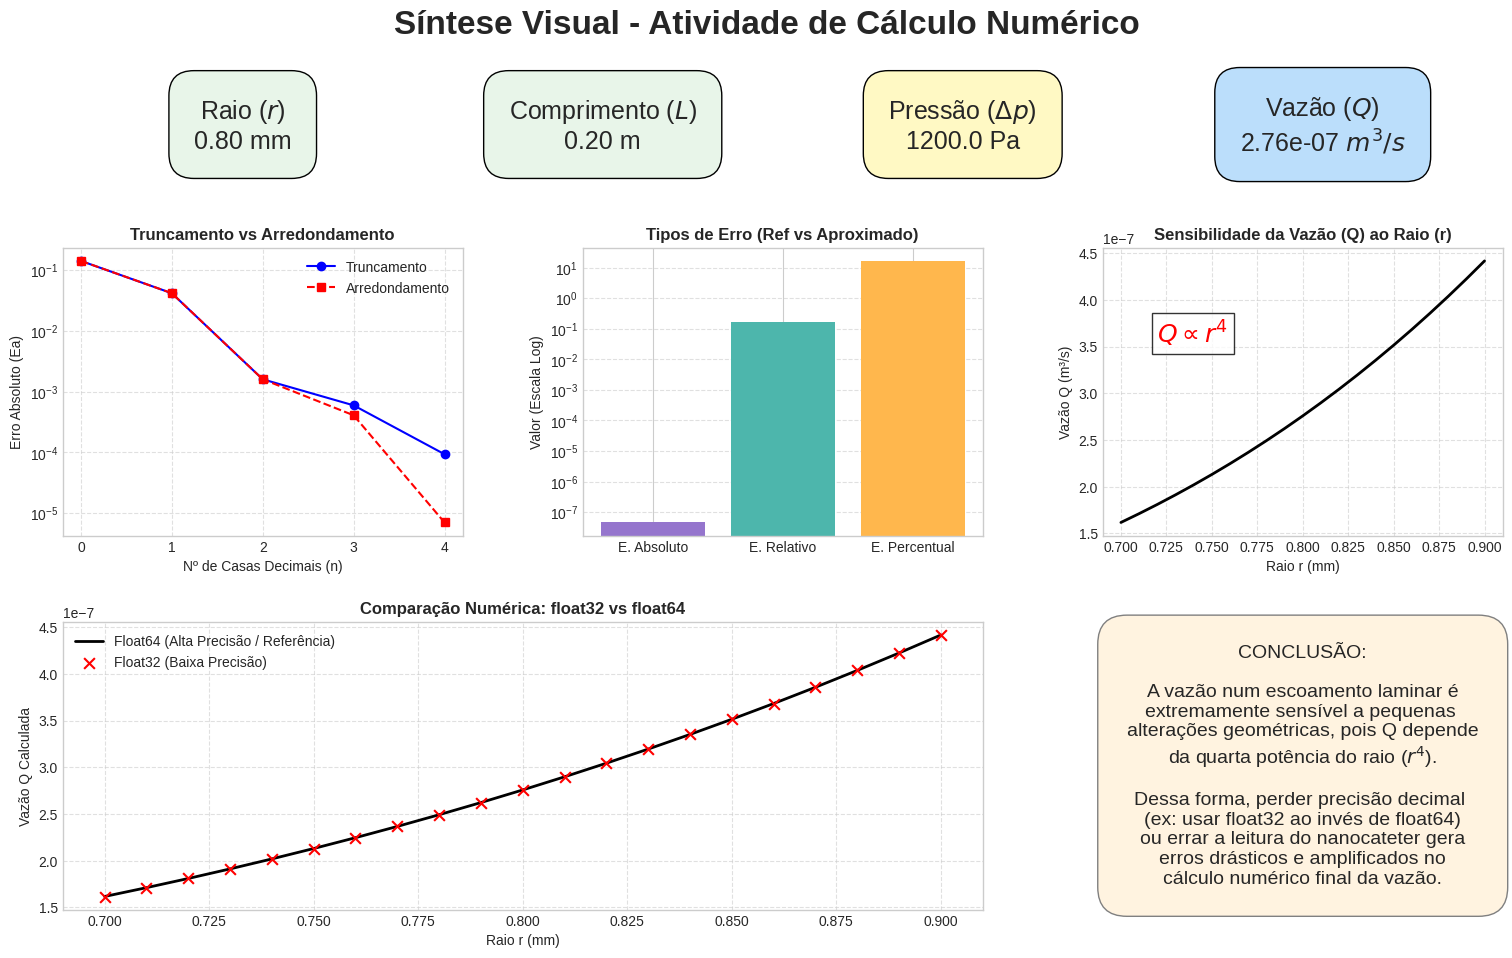

Imagem 'quadro_unico_E.png' salva com sucesso em exatos 1600x1000 pixels!


In [6]:
# ==========================================
# 1. PARÂMETROS E DADOS DA ATIVIDADE
# ==========================================
# Parâmetros de Hagen-Poiseuille (Parte C)
r_ref = 0.80       # mm
L_ref = 0.20       # m
mu_ref = 3.5e-3    # Pa.s
dp_ref = 1200.0    # Pa

# Calculando a vazão de referência
r_m = r_ref * 1e-3
Q_ref = (np.pi * (r_m ** 4) * dp_ref) / (8 * mu_ref * L_ref)

# Dados Truncamento vs Arredondamento (Pi como exemplo da Parte A)
n_casas = [0, 1, 2, 3, 4]
ea_trunc = [0.141593, 0.041593, 0.001593, 0.000593, 0.000093]
ea_round = [0.141593, 0.041593, 0.001593, 0.000407, 0.000007]

# Dados Tipos de Erro (Baseado no cenário de mu aproximado da Parte C.1)
tipos_erro = ['E. Absoluto', 'E. Relativo', 'E. Percentual']
erros_valores = [4.59e-8, 0.166, 16.6] # Escala log exigirá valores absolutos não nulos

# Dados Sensibilidade e Precisão Float (Parte C.2)
raios_mm = np.linspace(0.70, 0.90, 21)
raios_m = raios_mm * 1e-3

# Cálculo Float64 (Padrão do Numpy)
Q_f64 = (np.pi * raios_m**4 * dp_ref) / (8 * mu_ref * L_ref)

# Cálculo Float32 (Forçando baixa precisão computacional)
raios_f32 = np.float32(raios_m)
Q_f32 = (np.float32(np.pi) * raios_f32**np.float32(4) * np.float32(dp_ref)) / (np.float32(8) * np.float32(mu_ref) * np.float32(L_ref))


# ==========================================
# 2. MONTAGEM DO QUADRO VISUAL (1600x1000 px)
# ==========================================
# figsize=(16, 10) e dpi=100 garante os 1600x1000 pixels exatos
fig = plt.figure(figsize=(16, 10), dpi=100)
fig.suptitle('Síntese Visual - Atividade de Cálculo Numérico', fontsize=24, fontweight='bold')

# GridSpec com height_ratios para dar menos espaço pros cartões e mais pros gráficos
gs = gridspec.GridSpec(3, 3, figure=fig, height_ratios=[0.5, 2, 2], hspace=0.4, wspace=0.3)


# --- SEÇÃO 1: Cartões ---
ax_cards = fig.add_subplot(gs[0, :])
ax_cards.axis('off')
ax_cards.set_xlim(0, 1) # Fixa os limites para o texto não se perder
ax_cards.set_ylim(0, 1)

# Desenhando os 4 cartões
ax_cards.text(0.125, 0.5, f'Raio ($r$)\n{r_ref:.2f} mm', fontsize=18, ha='center', va='center', bbox=dict(facecolor='#E8F5E9', edgecolor='black', boxstyle='round,pad=1'))
ax_cards.text(0.375, 0.5, f'Comprimento ($L$)\n{L_ref:.2f} m', fontsize=18, ha='center', va='center', bbox=dict(facecolor='#E8F5E9', edgecolor='black', boxstyle='round,pad=1'))
ax_cards.text(0.625, 0.5, f'Pressão ($\\Delta p$)\n{dp_ref} Pa', fontsize=18, ha='center', va='center', bbox=dict(facecolor='#FFF9C4', edgecolor='black', boxstyle='round,pad=1'))
ax_cards.text(0.875, 0.5, f'Vazão ($Q$)\n{Q_ref:.2e} $m^3/s$', fontsize=18, ha='center', va='center', bbox=dict(facecolor='#BBDEFB', edgecolor='black', boxstyle='round,pad=1'))


# --- SEÇÃO 2: Comparação Truncamento vs Arredondamento ---
ax_trunc = fig.add_subplot(gs[1, 0])
ax_trunc.plot(n_casas, ea_trunc, marker='o', label='Truncamento', color='blue')
ax_trunc.plot(n_casas, ea_round, marker='s', linestyle='--', label='Arredondamento', color='red')
ax_trunc.set_yscale('log')
ax_trunc.set_xticks(n_casas)
ax_trunc.set_xlabel('Nº de Casas Decimais (n)')
ax_trunc.set_ylabel('Erro Absoluto (Ea)')
ax_trunc.set_title('Truncamento vs Arredondamento', fontweight='bold')
ax_trunc.legend()
ax_trunc.grid(True, linestyle='--', alpha=0.6)


# --- SEÇÃO 3: Os três tipos de Erro ---
ax_erros = fig.add_subplot(gs[1, 1])
ax_erros.bar(tipos_erro, erros_valores, color=['#9575CD', '#4DB6AC', '#FFB74D'])
ax_erros.set_yscale('log') # Log útil para ver valores distantes (10^-8 vs 10^1)
ax_erros.set_ylabel('Valor (Escala Log)')
ax_erros.set_title('Tipos de Erro (Ref vs Aproximado)', fontweight='bold')
ax_erros.grid(axis='y', linestyle='--', alpha=0.6)


# --- SEÇÃO 4: Sensibilidade de Q ao raio ---
ax_sens = fig.add_subplot(gs[1, 2])
ax_sens.plot(raios_mm, Q_f64, color='black', linewidth=2)
ax_sens.set_xlabel('Raio r (mm)')
ax_sens.set_ylabel('Vazão Q (m³/s)')
ax_sens.set_title('Sensibilidade da Vazão (Q) ao Raio (r)', fontweight='bold')
ax_sens.grid(True, linestyle='--', alpha=0.6)
ax_sens.text(0.72, Q_f64.max() * 0.8, r'$Q \propto r^4$', fontsize=18, color='red', bbox=dict(facecolor='white', alpha=0.8))


# --- SEÇÃO 5: Comparação float32 e float64 ---
ax_float = fig.add_subplot(gs[2, 0:2])
ax_float.plot(raios_mm, Q_f64, label='Float64 (Alta Precisão / Referência)', color='black', linewidth=2)
ax_float.scatter(raios_mm, Q_f32, label='Float32 (Baixa Precisão)', color='red', marker='x', s=60, zorder=5)
ax_float.set_xlabel('Raio r (mm)')
ax_float.set_ylabel('Vazão Q Calculada')
ax_float.set_title('Comparação Numérica: float32 vs float64', fontweight='bold')
ax_float.legend()
ax_float.grid(True, linestyle='--', alpha=0.6)


# --- SEÇÃO 6: Conclusão ---
ax_conc = fig.add_subplot(gs[2, 2])
ax_conc.axis('off')
ax_conc.set_xlim(0, 1)
ax_conc.set_ylim(0, 1)

texto_conclusao = (
    "CONCLUSÃO:\n\n"
    "A vazão num escoamento laminar é\n"
    "extremamente sensível a pequenas \n"
    "alterações geométricas, pois Q depende\n"
    "da quarta potência do raio ($r^4$).\n\n"
    "Dessa forma, perder precisão decimal \n"
    "(ex: usar float32 ao invés de float64)\n"
    "ou errar a leitura do nanocateter gera\n"
    "erros drásticos e amplificados no\n"
    "cálculo numérico final da vazão."
)
ax_conc.text(0.5, 0.5, texto_conclusao, fontsize=14, ha='center', va='center',
             bbox=dict(facecolor='#FFF3E0', edgecolor='gray', boxstyle='round,pad=1.5'))


# Ajuste fixo de layout para não cortar nada (Substituindo o tight_layout)
plt.subplots_adjust(top=0.90, bottom=0.08, left=0.06, right=0.96)

# Salvando exatamente o que foi montado, sem o bbox_inches='tight' bagunçar o tamanho final
plt.savefig('quadro_unico_E.png', format='png', dpi=100)
plt.show()

print("Imagem 'quadro_unico_E.png' salva com sucesso em exatos 1600x1000 pixels!")

Gerando GIF, aguarde alguns segundos...
O GIF 'animacao_nanocateter.gif' foi salvo na pasta do Colab!


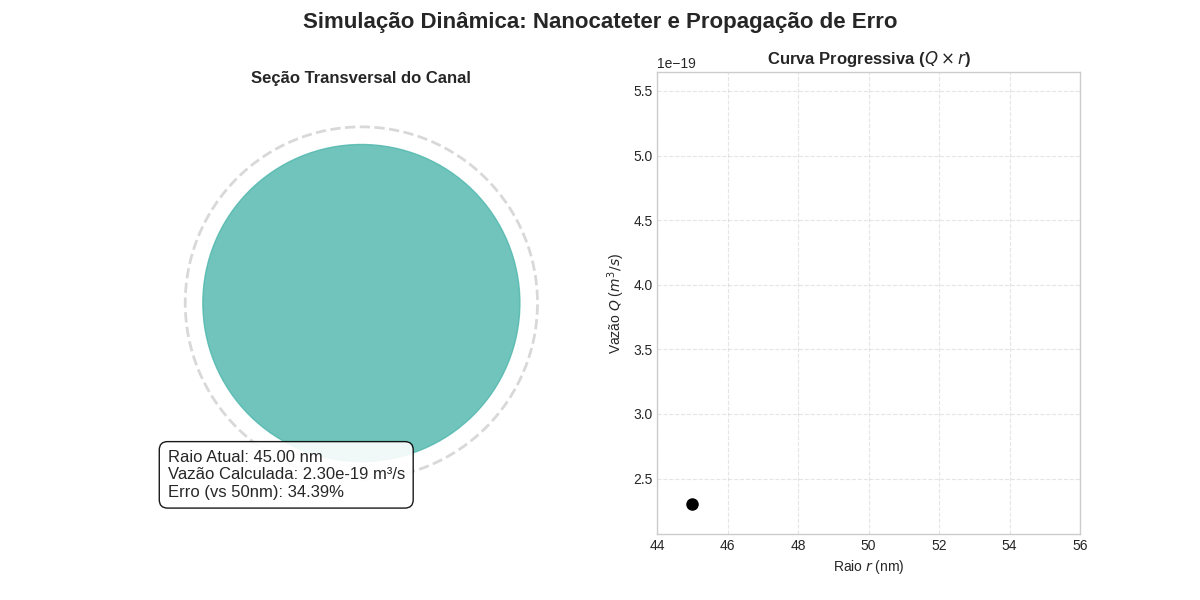

In [5]:
# 1. Parâmetros do Nanocateter (Baseado na Tarefa D)
L = 10e-6         # m
mu = 3.5e-3       # Pa.s
dp = 5000         # Pa
r_ref_nm = 50     # Referência em nm
r_ref = r_ref_nm * 1e-9

def calc_Q(r):
    return (np.pi * r**4 * dp) / (8 * mu * L)

Q_ref = calc_Q(r_ref)

# 2. Preparando os Dados da Animação (30 a 60 quadros)
num_frames = 50 # Escolhemos 50 quadros
raios_nm = np.linspace(45, 55, num_frames)
raios_m = raios_nm * 1e-9
vazoes = calc_Q(raios_m)

# 3. Configurando a Figura Visual
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6), dpi=100)
fig.suptitle('Simulação Dinâmica: Nanocateter e Propagação de Erro', fontsize=16, fontweight='bold')

# Subplot 1: Seção Transversal e Textos
ax1.set_xlim(-60, 60)
ax1.set_ylim(-60, 60)
ax1.set_aspect('equal') # Mantém o círculo perfeitamente redondo
ax1.axis('off')
ax1.set_title('Seção Transversal do Canal', fontweight='bold')

# Desenhando o Círculo de Referência (Fixo)
circle_ref = plt.Circle((0, 0), r_ref_nm, color='gray', alpha=0.3, linestyle='--', fill=False, linewidth=2)
ax1.add_patch(circle_ref)

# Desenhando o Círculo Dinâmico
circle_anim = plt.Circle((0, 0), raios_nm[0], color='#4DB6AC', alpha=0.8)
ax1.add_patch(circle_anim)

# Caixa de Texto para os dados (Raio, Q, Erro)
text_info = ax1.text(-55, -55, '', fontsize=12, bbox=dict(facecolor='white', edgecolor='black', alpha=0.9, boxstyle='round,pad=0.5'))

# Subplot 2: Curva Progressiva Q x r
ax2.set_xlim(44, 56)
ax2.set_ylim(vazoes.min() * 0.9, vazoes.max() * 1.1)
ax2.set_xlabel('Raio $r$ (nm)')
ax2.set_ylabel('Vazão $Q$ ($m^3/s$)')
ax2.set_title('Curva Progressiva ($Q \\times r$)', fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.5)

linha_curva, = ax2.plot([], [], color='red', linewidth=2.5)
ponto_atual, = ax2.plot([], [], 'ko', markersize=8) # Ponto preto rastreador

# 4. Funções de Animação
def init():
    circle_anim.set_radius(raios_nm[0])
    text_info.set_text('')
    linha_curva.set_data([], [])
    ponto_atual.set_data([], [])
    return circle_anim, text_info, linha_curva, ponto_atual

def update(frame):
    r_atual_nm = raios_nm[frame]
    Q_atual = vazoes[frame]

    # Atualiza o raio visual
    circle_anim.set_radius(r_atual_nm)

    # Atualiza os dados de texto
    erro_percentual = abs(Q_atual - Q_ref) / Q_ref * 100
    texto = (f"Raio Atual: {r_atual_nm:.2f} nm\n"
             f"Vazão Calculada: {Q_atual:.2e} m³/s\n"
             f"Erro (vs 50nm): {erro_percentual:.2f}%")
    text_info.set_text(texto)

    # Atualiza o traçado do gráfico
    linha_curva.set_data(raios_nm[:frame+1], vazoes[:frame+1])
    ponto_atual.set_data([r_atual_nm], [Q_atual])

    return circle_anim, text_info, linha_curva, ponto_atual

# 5. Renderizando e Salvando o GIF
print("Gerando GIF, aguarde alguns segundos...")
anim = FuncAnimation(fig, update, frames=num_frames, init_func=init, blit=True)

# Exportando usando o Pillow (15 frames por segundo dá um ritmo suave)
anim.save('animacao_nanocateter.gif', dpi=100, writer=PillowWriter(fps=15))
plt.close()
print("O GIF 'animacao_nanocateter.gif' foi salvo na pasta do Colab!")

# Exibe o GIF diretamente na saída da célula no Colab
Image(filename='animacao_nanocateter.gif')